# 03 · Alert rules: how good would an alert be?

**Case study 7: cutting unplanned downtime on a machine fleet** · Phase 4b, notebook 3 of 3 · answers **Q4**

Notebooks 01 and 02 found two kinds of warning before a failure: error codes, and sensors leaving their control limits. Either one alone raises many false alarms. This notebook turns them into simple alert rules that a maintenance team could run, and scores each rule against the real 2015 failures.

| Measure | Definition |
| --- | --- |
| Alert | The hour a rule's condition is met. More firings on the same machine within 7 days are the same alert (one inspection, not seven). No alerts in the 48 hours after a part replacement, while the daily mean still contains pre-repair readings. |
| True alert | A failure event on the same machine within 7 days after the alert |
| False alarm | An alert with no failure in the next 7 days: an inspection that finds nothing |
| Recall | Share of failure events caught (an alert in the 7 days before) |
| Precision | Share of alerts that are true |
| Lead time | Hours from the first alert to the failure. Failures are logged once a day, so read it to about a day. |

**Avoiding overfitting.** Everything is chosen on **January–August** (the training period): which sensor and error code go with which component, the thresholds, and the final rule. Only then is the chosen rule scored on **September–December** (the test period), which played no part in the choice. The test numbers are the ones to quote.

Outputs: `data/exports/alert_*.csv` for the Excel business case, and charts in `images/`.

> The dataset is synthetic. Findings show what this method would reveal on real plant data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import pdm
from pdm import INK, INK_2, MUTED, AXIS, SERIES, CRITICAL, SENSORS, SENSOR_LABEL, COMPONENTS, TRAIN, TEST

pdm.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:.3f}".format)

raw = pdm.load_raw()
tel, errors, failures, maint = raw["telemetry"], raw["errors"], raw["failures"], raw["maint"]
events = pdm.failure_events(failures)

tel = pdm.add_daily_mean(tel)
limits = pdm.baseline_limits(tel, events)          # January baseline: inside the training period
tel = pdm.add_z(tel, limits)
settled = ~(pdm.hours_since_replacement(tel, maint) < 48)
in_train = ((tel["datetime"] >= TRAIN[0]) & (tel["datetime"] < TRAIN[1])).values

def period_count(df, period):
    return int(((df["datetime"] >= period[0]) & (df["datetime"] < period[1])).sum())

print(f"Training period: {TRAIN[0]:%d %b %Y} to {TRAIN[1]:%d %b %Y}, {period_count(events, TRAIN)} failure events")
print(f"Test period:     {TEST[0]:%d %b %Y} to {TEST[1]:%d %b %Y}, {period_count(events, TEST)} failure events")

Training period: 01 Jan 2015 to 01 Sep 2015, 493 failure events
Test period:     01 Sep 2015 to 02 Jan 2016, 226 failure events


## 1. Learn the warning signs from the training period only

For each component, which sensor moves in the 48 hours before it fails, in which direction, and which error codes come before it?

In [2]:
# 48 h before each TRAINING failure, per component
train_fail = failures[(failures["datetime"] >= TRAIN[0]) & (failures["datetime"] < TRAIN[1])]
z_cols = [f"{s}_z" for s in SENSORS]
zt = tel.set_index(["machine_id", "datetime"])[z_cols]
pre = []
for f in train_fail.itertuples():
    idx = pd.MultiIndex.from_arrays([np.full(48, f.machine_id), f.datetime - pd.to_timedelta(np.arange(1, 49), unit="h")])
    pre.append(pd.DataFrame(zt.reindex(idx).to_numpy(), columns=SENSORS).assign(comp=f.comp))
sensor_shift = pd.concat(pre).groupby("comp")[SENSORS].mean()

# share of training failures with each error code in the 48 h before
rows = []
for f in train_fail.itertuples():
    e = errors[(errors["machine_id"] == f.machine_id)
               & (errors["datetime"] >= f.datetime - pd.Timedelta(hours=48)) & (errors["datetime"] < f.datetime)]
    rows.append({"comp": f.comp, **{code: code in set(e["error_id"]) for code in sorted(errors["error_id"].unique())}})
error_share = pd.DataFrame(rows).groupby("comp").mean()

signatures = pd.DataFrame({
    "sensor": sensor_shift.abs().idxmax(axis=1),
    "direction": [int(np.sign(sensor_shift.loc[c, sensor_shift.abs().idxmax(axis=1)[c]])) for c in sensor_shift.index],
    "mean_shift_sigma": [sensor_shift.loc[c].abs().max() for c in sensor_shift.index],
    "error_codes": [sorted(error_share.columns[error_share.loc[c] > 0.5]) for c in error_share.index],
    "failures_with_those_codes": [error_share.loc[c, error_share.columns[error_share.loc[c] > 0.5]].min() for c in error_share.index],
})
print("Mean shift of each sensor in the 48 h before a failure (σ from the machine's normal):")
display(sensor_shift.round(2))
print("Share of failures with each error code in the 48 h before:")
display(error_share.round(2))
signatures

Mean shift of each sensor in the 48 h before a failure (σ from the machine's normal):


,volt,rotate,pressure,vibration
comp,,,,
comp1,4.400,-0.490,0.210,0.110
comp2,0.260,-5.190,0.230,0.640
comp3,0.240,-0.290,8.250,0.430
comp4,0.160,-0.590,0.470,7.240


Share of failures with each error code in the 48 h before:


,error1,error2,error3,error4,error5
comp,,,,,
comp1,0.940,0.060,0.090,0.050,0.020
comp2,0.090,0.980,0.980,0.050,0.060
comp3,0.050,0.040,0.100,0.970,0.070
comp4,0.080,0.160,0.140,0.070,0.980


,sensor,direction,mean_shift_sigma,error_codes,failures_with_those_codes
comp,,,,,
comp1,volt,1,4.404,[error1],0.943
comp2,rotate,-1,5.188,"[error2, error3]",0.982
comp3,pressure,1,8.254,[error4],0.967
comp4,vibration,1,7.239,[error5],0.975


The training data gives a clean mapping, and it matches what notebooks 01–02 and the SQL found on the full year:

| Component | Sensor signature | Error code(s) |
| --- | --- | --- |
| comp1 | voltage rises | error1 |
| comp2 | rotation falls | error2, error3 |
| comp3 | pressure rises | error4 |
| comp4 | vibration rises | error5 |

## 2. The candidate rules

Five rule families, from the simplest to the most specific. Each is tried at several thresholds on the training period.

| Rule | Condition (checked every hour) |
| --- | --- |
| A. Vibration only | 24-hour mean vibration above its upper control limit for 6 hours in a row (the example in the project brief) |
| B. Any sensor | Any sensor beyond its limit, in its signature direction, for 1 or 6 hours in a row |
| C. Any error code | An error code is logged |
| D. Sensor + any error | Rule B, and any error code in the last 24 hours |
| E. Signature match | A sensor beyond its limit, and **that sensor's own** error code in the last 24 hours |

In [3]:
direction = {row.sensor: row.direction for row in signatures.itertuples()}
sensor_codes = {row.sensor: row.error_codes for row in signatures.itertuples()}
sensor_comp = {row.sensor: comp for comp, row in signatures.iterrows()}

any_error_24h = pdm.recent_error(tel, errors, None, 24)
code_24h = {s: pdm.recent_error(tel, errors, sensor_codes[s], 24) for s in SENSORS}
error_now = pdm.recent_error(tel, errors, None, 1)

def beyond(s, k):
    return (direction[s] * tel[f"{s}_z"].values) > k

def rule_flags(rule, k=3.0):
    """Hourly True/False condition for a rule at threshold k (σ)."""
    if rule == "A":
        return beyond("vibration", k)
    if rule == "B":
        return np.logical_or.reduce([beyond(s, k) for s in SENSORS])
    if rule == "C":
        return error_now
    if rule == "D":
        return np.logical_or.reduce([beyond(s, k) for s in SENSORS]) & any_error_24h
    if rule == "E":
        return np.logical_or.reduce([beyond(s, k) & code_24h[s] for s in SENSORS])

RULE_NAMES = {"A": "A. Vibration only", "B": "B. Any sensor", "C": "C. Any error code",
              "D": "D. Sensor + any error", "E": "E. Signature match"}

def run_rule(rule, k=3.0, hours=1):
    flag = rule_flags(rule, k) & settled
    return pdm.alerts_from_flag(tel, flag, min_hours=hours, merge_days=7)

variants = [("A", 3.0, 6), ("C", None, 1)]
variants += [(r, k, h) for r in ["B", "D", "E"] for k in [2.0, 2.5, 3.0, 3.5, 4.0] for h in [1, 6]]

results, alert_sets = [], {}
for rule, k, h in variants:
    alerts = run_rule(rule, k if k is not None else 3.0, h)
    alert_sets[(rule, k, h)] = alerts
    for name, period in [("train", TRAIN), ("test", TEST)]:
        results.append({"rule": rule, "rule_name": RULE_NAMES[rule], "threshold_sigma": k, "hours_in_a_row": h,
                        "period": name, **pdm.score(alerts, events, period)})
results = pd.DataFrame(results)
train = results[results["period"] == "train"].drop(columns="period")
train.sort_values(["rule", "threshold_sigma", "hours_in_a_row"])[
    ["rule_name", "threshold_sigma", "hours_in_a_row", "alerts", "caught", "failures", "recall", "precision", "median_lead_hours"]]

,rule_name,threshold_sigma,hours_in_a_row,alerts,caught,failures,recall,precision,median_lead_hours
0,A. Vibration only,3.000,6,432,137,493,0.278,0.317,37.000
4,B. Any sensor,2.000,1,2669,474,493,0.961,0.178,48.000
6,B. Any sensor,2.000,6,2044,472,493,0.957,0.231,40.000
8,B. Any sensor,2.500,1,2138,469,493,0.951,0.219,44.000
10,B. Any sensor,2.500,6,1605,465,493,0.943,0.290,38.000
12,B. Any sensor,3.000,1,1689,462,493,0.937,0.274,42.000
14,B. Any sensor,3.000,6,1342,446,493,0.905,0.332,37.000
16,B. Any sensor,3.500,1,1354,436,493,0.884,0.322,41.000
18,B. Any sensor,3.500,6,1184,424,493,0.860,0.358,36.000
20,B. Any sensor,4.000,1,1163,415,493,0.842,0.357,39.000


## 3. Choose one rule, on the training period only

The criterion, fixed before looking at the test period: **the highest precision among rules that catch at least 90% of failures**. Missing a failure is the expensive outcome, so recall comes first; among rules that keep it high, the fewest wasted inspections wins. If two rules tie on precision, the one with more notice wins.

In [4]:
best_per_rule = (train.sort_values(["precision", "median_lead_hours"], ascending=False)
                 .groupby("rule").head(1).sort_values("rule"))
eligible = train[train["recall"] >= 0.90].sort_values(["precision", "median_lead_hours"], ascending=False)
chosen = eligible.iloc[0]
CHOSEN = (chosen["rule"], chosen["threshold_sigma"], int(chosen["hours_in_a_row"]))
print(f"Chosen rule: {chosen['rule_name']}, threshold {chosen['threshold_sigma']}σ, {CHOSEN[2]} hour(s) in a row")
print(f"Training period: recall {chosen['recall']:.1%}, precision {chosen['precision']:.1%}, "
      f"median lead time {chosen['median_lead_hours']:.0f} h")

Chosen rule: E. Signature match, threshold 2.5σ, 6 hour(s) in a row
Training period: recall 93.9%, precision 89.6%, median lead time 19 h


## 4. Score on the test period (September–December)

For a fair comparison, each rule family is represented by its best training-period variant (highest precision, ignoring the 90% recall floor), then all are scored on the test period. The chosen rule is marked.

In [5]:
def best_variant(rule):
    t = train[train["rule"] == rule]
    if rule == CHOSEN[0]:
        return CHOSEN
    b = t.sort_values(["precision", "median_lead_hours"], ascending=False).iloc[0]
    return (rule, b["threshold_sigma"], int(b["hours_in_a_row"]))

reps = [best_variant(r) for r in "ABCDE"]
test = results[results["period"] == "test"]
rows = []
for rule, k, h in reps:
    tr = train[(train["rule"] == rule) & (train["threshold_sigma"].fillna(-1) == (k if k is not None and not pd.isna(k) else -1))
               & (train["hours_in_a_row"] == h)].iloc[0]
    te = test[(test["rule"] == rule) & (test["threshold_sigma"].fillna(-1) == (k if k is not None and not pd.isna(k) else -1))
              & (test["hours_in_a_row"] == h)].iloc[0]
    rows.append({"rule": RULE_NAMES[rule] + ("  ← chosen" if (rule, k, h) == CHOSEN else ""),
                 "threshold_sigma": k, "hours_in_a_row": h,
                 "train_recall": tr["recall"], "train_precision": tr["precision"],
                 "test_recall": te["recall"], "test_precision": te["precision"],
                 "test_failures": te["failures"], "test_caught": te["caught"], "test_alerts": te["alerts"],
                 "test_false_alarms": te["false_alarms"], "test_median_lead_hours": te["median_lead_hours"]})
comparison = pd.DataFrame(rows)
comparison

,rule,threshold_sigma,hours_in_a_row,train_recall,train_precision,test_recall,test_precision,test_failures,test_caught,test_alerts,test_false_alarms,test_median_lead_hours
0,A. Vibration only,3.000,6,0.278,0.317,0.283,0.279,226,64,229,165,37.000
1,B. Any sensor,4.000,6,0.801,0.374,0.792,0.316,226,179,567,388,33.000
2,C. Any error code,NaN,1,0.925,0.328,0.920,0.310,226,208,670,462,24.000
3,D. Sensor + any error,4.000,6,0.769,0.767,0.792,0.696,226,179,257,78,19.000
4,E. Signature match ← chosen,2.500,6,0.939,0.896,0.973,0.859,226,220,256,36,19.000


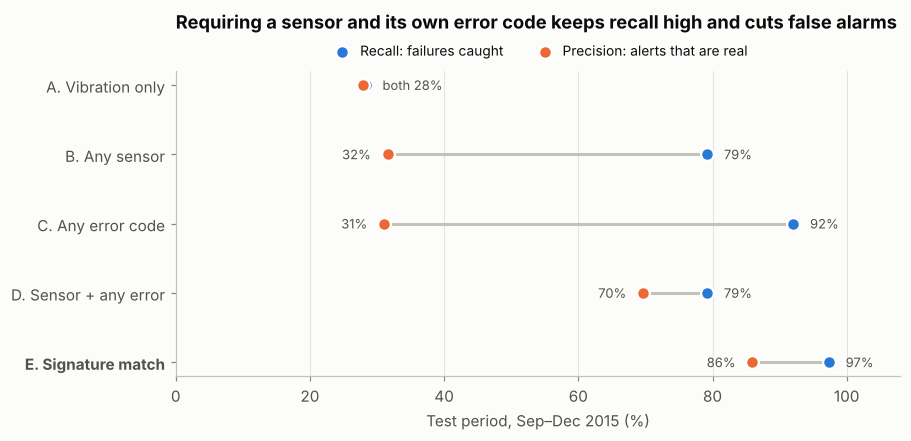

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
c = comparison.iloc[::-1].reset_index(drop=True)
labels = [r.replace("  ← chosen", "") for r in c["rule"]]
for y, r in c.iterrows():
    ax.plot([r["test_precision"] * 100, r["test_recall"] * 100], [y, y], color=AXIS, linewidth=2, zorder=1)
ax.scatter(c["test_recall"] * 100, range(len(c)), color=SERIES[0], s=70, zorder=2, label="Recall: failures caught",
           edgecolor="white", linewidth=1.5)
ax.scatter(c["test_precision"] * 100, range(len(c)), color=SERIES[1], s=70, zorder=2, label="Precision: alerts that are real",
           edgecolor="white", linewidth=1.5)
for y, r in c.iterrows():
    rec, pre = r["test_recall"] * 100, r["test_precision"] * 100
    if abs(rec - pre) < 5:   # dots overlap: one label for both
        ax.text(max(rec, pre) + 2.5, y, f"both {rec:.0f}%", va="center", color=INK_2, fontsize=8.5)
    else:
        ax.text(rec + 2.5, y, f"{rec:.0f}%", va="center", color=INK_2, fontsize=8.5)
        ax.text(pre - 2.5, y, f"{pre:.0f}%", va="center", ha="right", color=INK_2, fontsize=8.5)
ax.set_yticks(range(len(c)), labels)
chosen_y = [i for i, r in enumerate(c["rule"]) if "chosen" in r][0]
ax.get_yticklabels()[chosen_y].set_fontweight("bold")
ax.set_xlim(0, 108)
ax.set_xlabel("Test period, Sep–Dec 2015 (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=9, handletextpad=0.3)
ax.set_title("Requiring a sensor and its own error code keeps recall high and cuts false alarms", pad=28)
pdm.save(fig, "q4_rule_comparison.png")
plt.show()

### The chosen rule on the test period

In [7]:
chosen_alerts = alert_sets[CHOSEN]
lo, hi = TEST
a_test = chosen_alerts[(chosen_alerts["datetime"] >= lo) & (chosen_alerts["datetime"] < hi)].reset_index(drop=True)
e_test = events[(events["datetime"] >= lo) & (events["datetime"] < hi)].reset_index(drop=True)
a_test, e_test = pdm.match_alerts(a_test, e_test)
s = pdm.score(chosen_alerts, events, TEST)

summary = pd.DataFrame({
    "": ["Failure events", "  caught (an alert in the 7 days before)", "  missed",
         "Alerts", "  true (a failure followed within 7 days)", "  false alarms",
         "Recall", "Precision", "Median lead time (hours)"],
    "Sep–Dec 2015": [s["failures"], s["caught"], s["missed"], s["alerts"], s["true_alerts"], s["false_alarms"],
                     f"{s['recall']:.1%}", f"{s['precision']:.1%}", f"{s['median_lead_hours']:.0f}"],
})
summary

,,Sep–Dec 2015
0,Failure events,226
1,caught (an alert in the 7 days before),220
2,missed,6
3,Alerts,256
4,true (a failure followed within 7 days),220
5,false alarms,36
6,Recall,97.3%
7,Precision,85.9%
8,Median lead time (hours),19


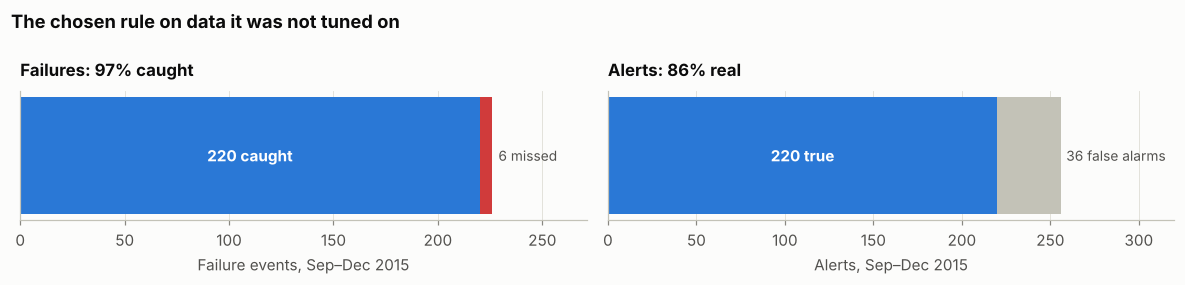

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.6), gridspec_kw={"width_ratios": [1, 1]})
ax = axes[0]
ax.barh([0], [s["caught"]], color=SERIES[0], height=0.5)
ax.barh([0], [s["missed"]], left=[s["caught"]], color=CRITICAL, height=0.5)
ax.text(s["caught"] / 2, 0, f"{s['caught']} caught", color="white", ha="center", va="center", fontsize=10, fontweight="bold")
ax.text(s["caught"] + s["missed"] + 3, 0, f"{s['missed']} missed", color=INK_2, va="center", fontsize=9)
ax.set_xlim(0, (s["caught"] + s["missed"]) * 1.2)
ax.set_title(f"Failures: {s['recall']:.0%} caught", fontsize=11)
ax.set_yticks([]); ax.set_xlabel("Failure events, Sep–Dec 2015"); ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh([0], [s["true_alerts"]], color=SERIES[0], height=0.5)
ax.barh([0], [s["false_alarms"]], left=[s["true_alerts"]], color=AXIS, height=0.5)
ax.text(s["true_alerts"] / 2, 0, f"{s['true_alerts']} true", color="white", ha="center", va="center", fontsize=10, fontweight="bold")
ax.text(s["alerts"] + 3, 0, f"{s['false_alarms']} false alarms", color=INK_2, va="center", fontsize=9)
ax.set_xlim(0, s["alerts"] * 1.25)
ax.set_title(f"Alerts: {s['precision']:.0%} real", fontsize=11)
ax.set_yticks([]); ax.set_xlabel("Alerts, Sep–Dec 2015"); ax.grid(axis="y", visible=False)
fig.suptitle("The chosen rule on data it was not tuned on", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
pdm.save(fig, "q4_chosen_rule_test.png")
plt.show()

### How much notice?

In [9]:
lead = e_test.loc[e_test["caught"], "lead_hours"]
print(f"Lead time over {len(lead)} caught failures, hours: min {lead.min():.0f}, median {lead.median():.0f}, max {lead.max():.0f}")
lead.value_counts().sort_index().rename("failures").to_frame()

Lead time over 220 caught failures, hours: min 3, median 19, max 156


,failures
lead_hours,
3.000,1
9.000,1
10.000,1
12.000,2
14.000,6
16.000,1
19.000,196
21.000,1
22.000,2


196 of the 220 caught failures get exactly 19 hours of notice. Failures are logged at 06:00, and the rule usually fires at 11:00 the day before, once the daily mean has been past its limit for 6 hours. Real data would spread out; here, the honest summary is **about 19 hours, so the alert gives most of a day**.

## 5. Stretch: does the rule work for every component?

The signature rule knows which sensor fired, so each alert names a component. Score each component's alerts against that component's failures, on the test period.

In [10]:
rows = []
rule, k, h = CHOSEN
for s_name in SENSORS:
    comp = sensor_comp[s_name]
    flag = beyond(s_name, k) & code_24h[s_name] & settled
    al = pdm.alerts_from_flag(tel, flag, min_hours=h, merge_days=7)
    comp_events = failures[failures["comp"] == comp][["machine_id", "datetime"]].reset_index(drop=True)
    rows.append({"component": comp, "sensor": s_name, "error_codes": ", ".join(sensor_codes[s_name]),
                 **pdm.score(al, comp_events, TEST)})
per_comp = pd.DataFrame(rows)[["component", "sensor", "error_codes", "failures", "caught", "alerts",
                               "false_alarms", "recall", "precision", "median_lead_hours"]]
per_comp

,component,sensor,error_codes,failures,caught,alerts,false_alarms,recall,precision,median_lead_hours
0,comp1,volt,error1,51,50,58,8,0.980,0.862,19.000
1,comp2,rotate,"error2, error3",91,89,111,22,0.978,0.802,19.000
2,comp3,pressure,error4,40,40,47,7,1.000,0.851,19.000
3,comp4,vibration,error5,57,53,57,4,0.930,0.930,19.000


## 6. Numbers for the business case

The Excel model (Phase 5) needs the rule's performance and its yearly volumes. Recall and precision come from the **test** period. Yearly counts come from running the chosen rule over the whole year, because the business case is a yearly budget.

In [11]:
full_year = (pd.Timestamp("2015-01-01"), pd.Timestamp("2016-01-02"))
chosen_summary = pd.DataFrame([
    {"period": name, "rule": RULE_NAMES[CHOSEN[0]], "threshold_sigma": CHOSEN[1], "hours_in_a_row": CHOSEN[2],
     **pdm.score(chosen_alerts, events, p)}
    for name, p in [("train (Jan-Aug)", TRAIN), ("test (Sep-Dec)", TEST), ("full year 2015", full_year)]
])

all_alerts, all_events = pdm.match_alerts(chosen_alerts.reset_index(drop=True), events.reset_index(drop=True))
all_alerts["period"] = np.where(all_alerts["datetime"] < TRAIN[1], "train", "test")

pdm.EXPORT_DIR.mkdir(exist_ok=True)
chosen_summary.to_csv(pdm.EXPORT_DIR / "alert_chosen_rule_summary.csv", index=False)
results.to_csv(pdm.EXPORT_DIR / "alert_rule_results.csv", index=False)
comparison.to_csv(pdm.EXPORT_DIR / "alert_rule_comparison.csv", index=False)
per_comp.to_csv(pdm.EXPORT_DIR / "alert_per_component_test.csv", index=False)
all_alerts.to_csv(pdm.EXPORT_DIR / "alert_chosen_rule_alerts.csv", index=False)
print("Wrote alert_chosen_rule_summary.csv, alert_rule_results.csv, alert_rule_comparison.csv, "
      "alert_per_component_test.csv, alert_chosen_rule_alerts.csv to data/exports/")
chosen_summary

Wrote alert_chosen_rule_summary.csv, alert_rule_results.csv, alert_rule_comparison.csv, alert_per_component_test.csv, alert_chosen_rule_alerts.csv to data/exports/


,period,rule,threshold_sigma,hours_in_a_row,failures,caught,missed,alerts,true_alerts,false_alarms,recall,precision,median_lead_hours
0,train (Jan-Aug),E. Signature match,2.500,6,493,463,30,517,463,54,0.939,0.896,19.000
1,test (Sep-Dec),E. Signature match,2.500,6,226,220,6,256,220,36,0.973,0.859,19.000
2,full year 2015,E. Signature match,2.500,6,719,685,34,773,685,88,0.953,0.886,19.000


## Findings (Q4)

- **The best rule needs two signals to agree.** Rule E fires when a sensor's daily mean leaves its control limit **and** that sensor's own error code appeared in the last 24 hours (voltage + error1, rotation + error2/3, pressure + error4, vibration + error5). It was chosen on January–August and then scored on September–December, data it had never seen.
- **On the test period it caught 220 of 226 failures (97%), and 220 of its 256 alerts were real (86%).** That is 36 false alarms in four months across 100 machines, about one inspection every three days that finds nothing. On the training period the figures were 94% and 90%, so the rule did not get worse on new data.
- **Single signals are not enough.** The brief's example (vibration above its limit for 6 hours) can only see comp4, so it caught 28% of failures. "Any sensor" and "any error code" caught 79% and 92%, but only about 1 alert in 3 was real.
- **The notice is short: about 19 hours.** That is enough to plan a repair into the next shift and have the part ready, not to plan weeks ahead. Failures are logged once a day, so lead times are accurate to about a day.
- **It works for every component.** On the test period, recall is 93–100% and precision 80–93% for each of comp1–comp4 (section 5), so one rule covers the whole fleet, and each alert says which part to check.
- **Caveat.** The data is synthetic, and its warning signs are much cleaner than a real plant's. On real data, expect lower precision and recall. The method (limits per machine, a rule chosen on one period and tested on another) carries over unchanged.

Next: the Excel business case, which prices these alerts against today's reactive and scheduled maintenance.